# Healthcare Fraud Detection - Exploratory Data Analysis

## Purpose

This notebook explores patterns, distributions, relationships, and visualizations in the healthcare fraud detection dataset.

*Author: Brandon Ismalej*

In [23]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
from pathlib import Path

In [24]:
warnings.filterwarnings("ignore")

# Display and plot defaults
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
%matplotlib inline

In [25]:
# Path to raw data
RAW_DATA_PATH = "../data/raw/healthcare_fraud_detection.csv"

In [26]:
# Import data
df = pd.read_csv(RAW_DATA_PATH)

df.head()


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.00
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.00
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.00
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.00
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.00


The dataset has 10,000 claims and 20 columns, covering IDs, patient info, claim amounts, provider info, and the `Is_Fraud` label.

In [27]:
# Summary stats for numeric columns
df.describe()

,Patient_Age,Procedure_Code,Claim_Amount,Approved_Amount,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Is_Fraud,Length_of_Stay,Chronic_Condition_Flag,Prior_Visits_12m
count,"10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","10,000.00","9,650.00"
mean,49.76,"86,905.21",572.80,475.51,14.41,68.63,0.08,2.20,0.29,3.03
std,17.91,"14,965.32",406.20,323.26,8.49,14.91,0.28,1.71,0.45,1.72
min,1.00,"36,415.00",60.21,50.35,0.00,42.00,0.00,0.00,0.00,0.00
25%,37.75,"80,053.00",305.20,257.20,7.00,60.00,0.00,1.00,0.00,2.00
50%,50.00,"93,000.00",461.23,388.37,14.00,66.00,0.00,2.00,0.00,3.00
75%,62.00,"99,213.00",711.37,598.35,22.00,72.00,0.00,3.00,1.00,4.00
max,95.00,"99,214.00","6,590.70","4,270.89",29.00,144.00,1.00,5.00,1.00,12.00


- `Is_Fraud` has a mean of 0.08, so about 8% of claims are fraud.
- `Claim_Amount`, `Approved_Amount`, and `Number_of_Claims_Per_Provider_Monthly` have maximums far above their 75th percentiles, suggesting right skew and outliers.
- `Prior_Visits_12m` has 9,650 values instead of 10,000, so some are missing.
- `Procedure_Code` is stored as a number but is really a category, so its stats aren't meaningful.

In [28]:
# Check missingness
print(df.isna().sum())

# Show percentages of missingness per column
missing = df.isna().mean().mul(100).round(2)
missing[missing > 0].sort_values(ascending=False)

Provider_ID                                0
Claim_ID                                   0
Patient_Age                                0
Patient_Gender                             0
Diagnosis_Code                             0
Procedure_Code                             0
Claim_Amount                               0
Approved_Amount                            0
Insurance_Type                           350
Claim_Submission_Date                      0
Days_Between_Service_and_Claim             0
Number_of_Claims_Per_Provider_Monthly      0
Provider_Specialty                       350
Patient_State                              0
Claim_Status                               0
Is_Fraud                                   0
Length_of_Stay                             0
Visit_Type                                 0
Chronic_Condition_Flag                     0
Prior_Visits_12m                         350
dtype: int64


Insurance_Type       3.50
Provider_Specialty   3.50
Prior_Visits_12m     3.50
dtype: float64

Only `Insurance_Type`, `Provider_Specialty`, and `Prior_Visits_12m` have missing values, each with 350 rows missing (3.5%). All other columns are complete.

In [29]:
# For columns with missing values, view what other values look like
cols_with_na = df.columns[df.isna().any()]

for col in cols_with_na:
    print(df[col].value_counts(dropna=False).head(10))
    print()

Insurance_Type
Medicare    2425
Medicaid    2419
Private     2405
Self-Pay    2401
NaN          350
Name: count, dtype: int64

Provider_Specialty
Internal Medicine    2019
General Practice     1878
Orthopedics          1616
Neurology            1516
Cardiology           1366
Pulmonology          1255
NaN                   350
Name: count, dtype: int64

Prior_Visits_12m
3.00    2177
2.00    2076
4.00    1696
1.00    1436
5.00     999
6.00     487
0.00     460
NaN      350
7.00     214
8.00      74
Name: count, dtype: int64



The non-missing values look clean. `Insurance_Type` is evenly split across 4 types, `Provider_Specialty` has 6 specialties, and `Prior_Visits_12m` is mostly 1–5 visits. There are no placeholder values like "Unknown" hiding extra missing data.

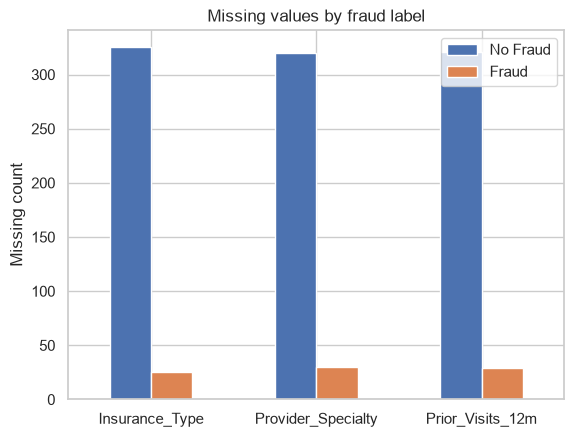

In [30]:
# Plot missing values by fraud label
cols = ["Insurance_Type", "Provider_Specialty", "Prior_Visits_12m"]

missing_by_fraud = df[cols].isna().groupby(df["Is_Fraud"]).sum().T
missing_by_fraud.columns = ["No Fraud", "Fraud"]

missing_by_fraud.plot(kind="bar")
plt.ylabel("Missing count")
plt.title("Missing values by fraud label")
plt.xticks(rotation=0)
plt.show()

Most missing values are in no-fraud rows, but that's because most claims are no fraud. As a percentage, about 3–3.5% of both fraud and no-fraud rows are missing in each column. Missingness doesn't appear to be a fraud signal, so these values can be imputed without losing information.

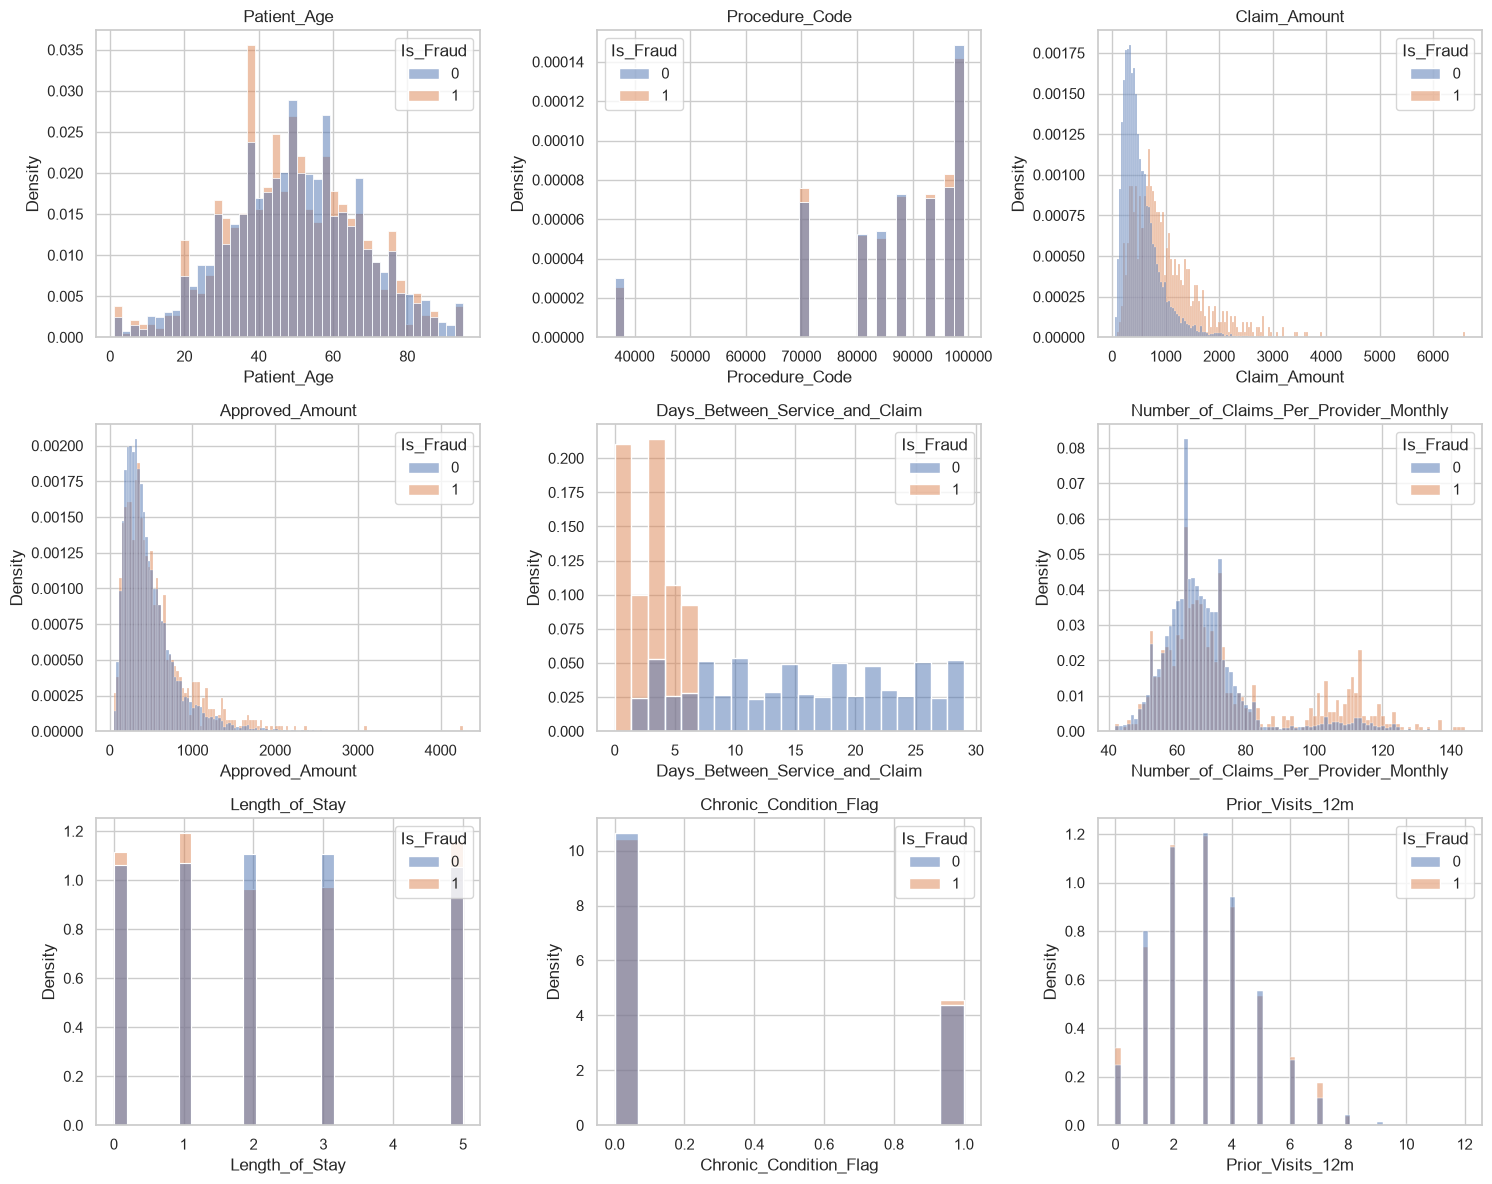

In [31]:
# Plot distribution of numeric columns by fraud label
num_cols = df.select_dtypes("number").columns.drop("Is_Fraud")

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, hue="Is_Fraud", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


Fraud claims stand out in two variables: they are submitted much sooner after service (`Days_Between_Service_and_Claim`) and have higher `Claim_Amount`. `Number_of_Claims_Per_Provider_Monthly` also has a longer right tail for fraud. The other variables look nearly the same for both classes.

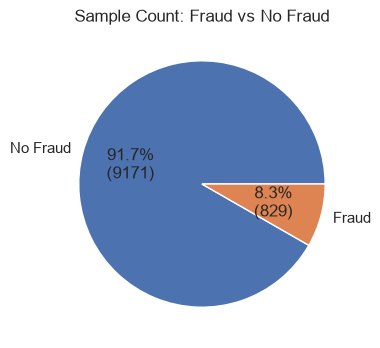

In [32]:
# Plot sample count of fraud vs no fraud
counts = df["Is_Fraud"].value_counts()

counts.plot(
    kind="pie",
    labels=["No Fraud", "Fraud"],
    autopct=lambda p: f"{p:.1f}%\n({p * counts.sum() / 100:.0f})",
    figsize=(4, 4),
)
plt.ylabel("")
plt.title("Sample Count: Fraud vs No Fraud")
plt.show()

The data is imbalanced: 91.7% of claims are no fraud (9,171) and 8.3% are fraud (829). Accuracy alone will be misleading when modeling, so metrics like recall, precision, and ROC-AUC should be used.

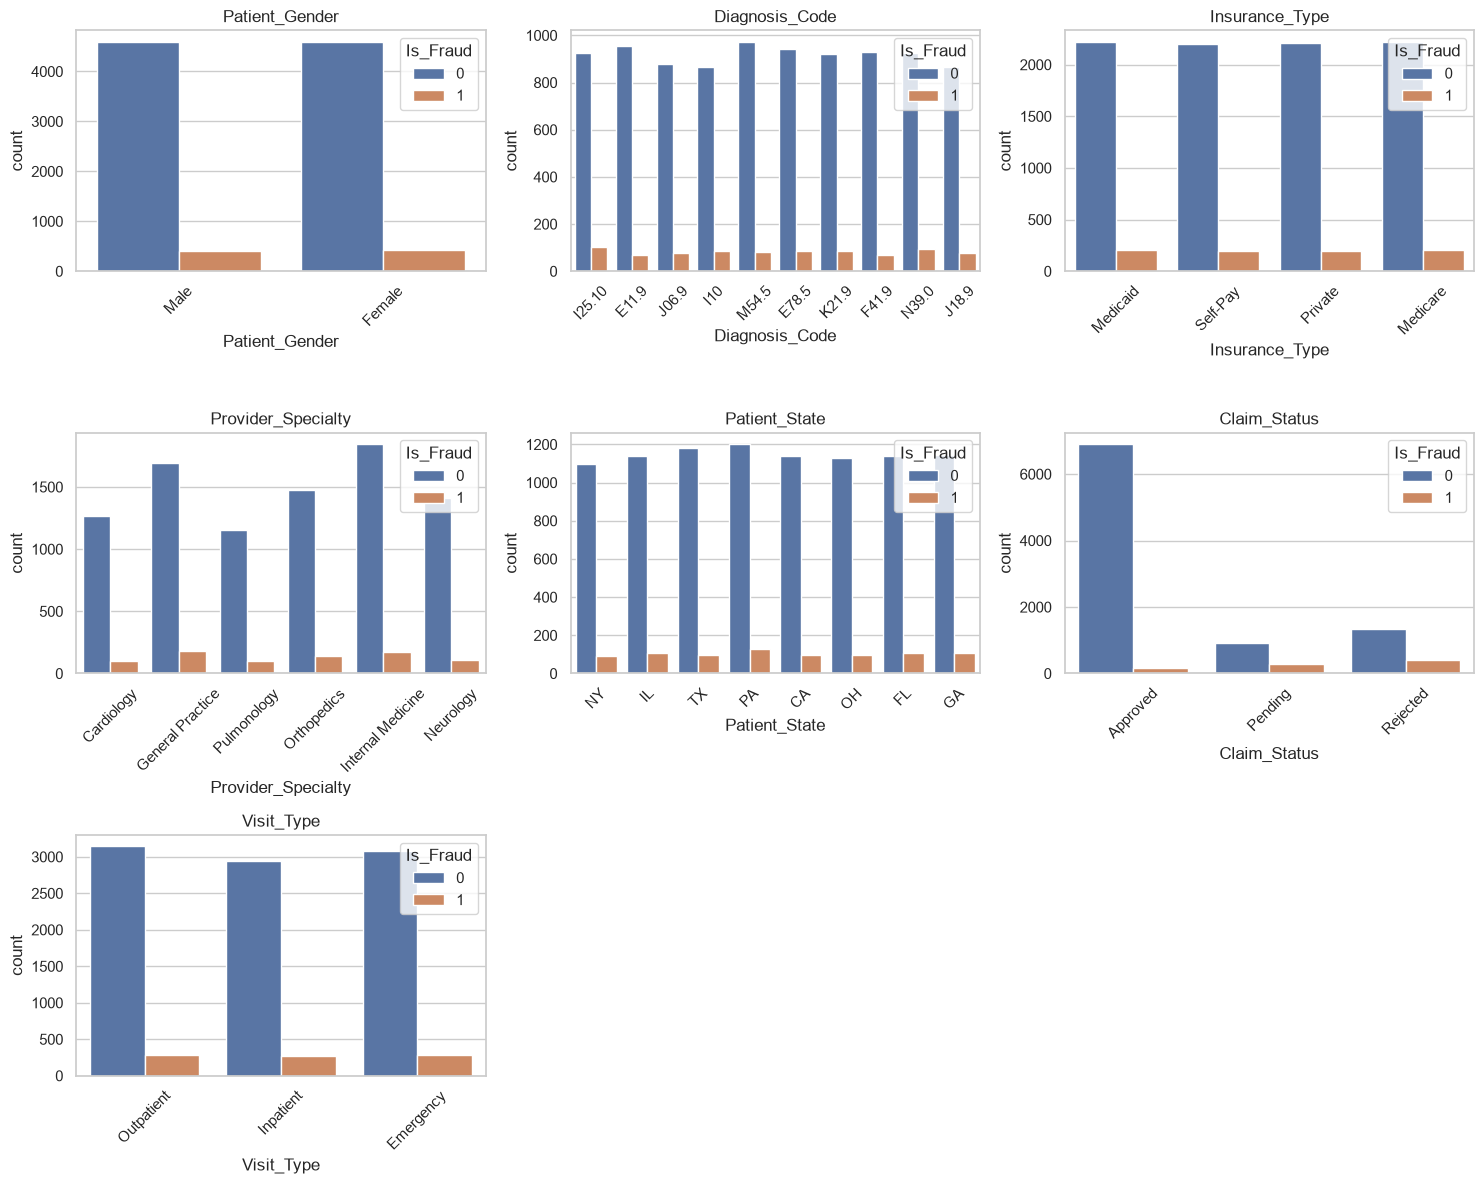

In [33]:
# Plot counts of categorical columns by fraud label
cat_cols = ["Patient_Gender", "Diagnosis_Code", "Insurance_Type", "Provider_Specialty",
            "Patient_State", "Claim_Status", "Visit_Type"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(data=df, x=col, hue="Is_Fraud", ax=ax)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Fraud shows up in every category, and for most variables the fraud bars follow the same shape as the no-fraud bars. `Claim_Status` is the exception: fraud is concentrated in Pending and Rejected claims.

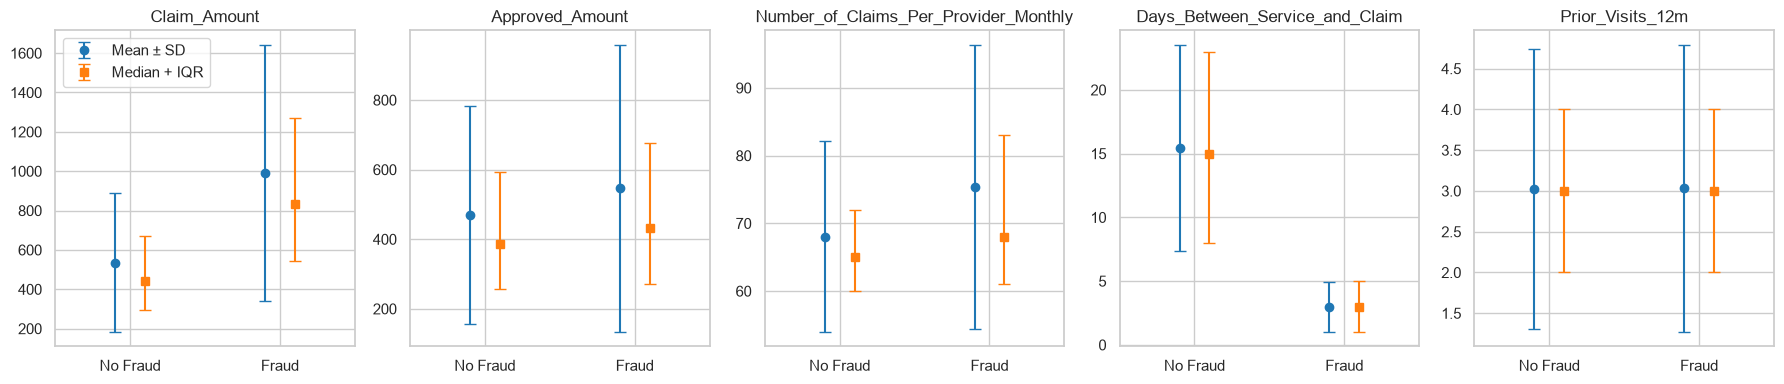

In [34]:
# Compare mean/SD and median/IQR of important variables by fraud label
important = ["Claim_Amount", "Approved_Amount", "Number_of_Claims_Per_Provider_Monthly",
             "Days_Between_Service_and_Claim", "Prior_Visits_12m"]

fig, axes = plt.subplots(1, len(important), figsize=(18, 4))

for ax, col in zip(axes, important):
    g = df.groupby("Is_Fraud")[col]
    mean, sd = g.mean(), g.std()
    median, q1, q3 = g.median(), g.quantile(0.25), g.quantile(0.75)
    x = np.array([0, 1])

    ax.errorbar(x - 0.1, mean, yerr=sd, fmt="o", color="tab:blue", capsize=4, label="Mean ± SD")
    ax.errorbar(x + 0.1, median, yerr=[median - q1, q3 - median], fmt="s", color="tab:orange", capsize=4, label="Median + IQR")

    ax.set_xticks(x, ["No Fraud", "Fraud"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_title(col)

axes[0].legend()
plt.tight_layout()
plt.show()


Fraud claims have a much higher `Claim_Amount` (median \$831 vs \$443) and are submitted much sooner after service (median 3 vs 15 days). `Approved_Amount` and `Number_of_Claims_Per_Provider_Monthly` are only slightly higher for fraud, and `Prior_Visits_12m` is the same for both.

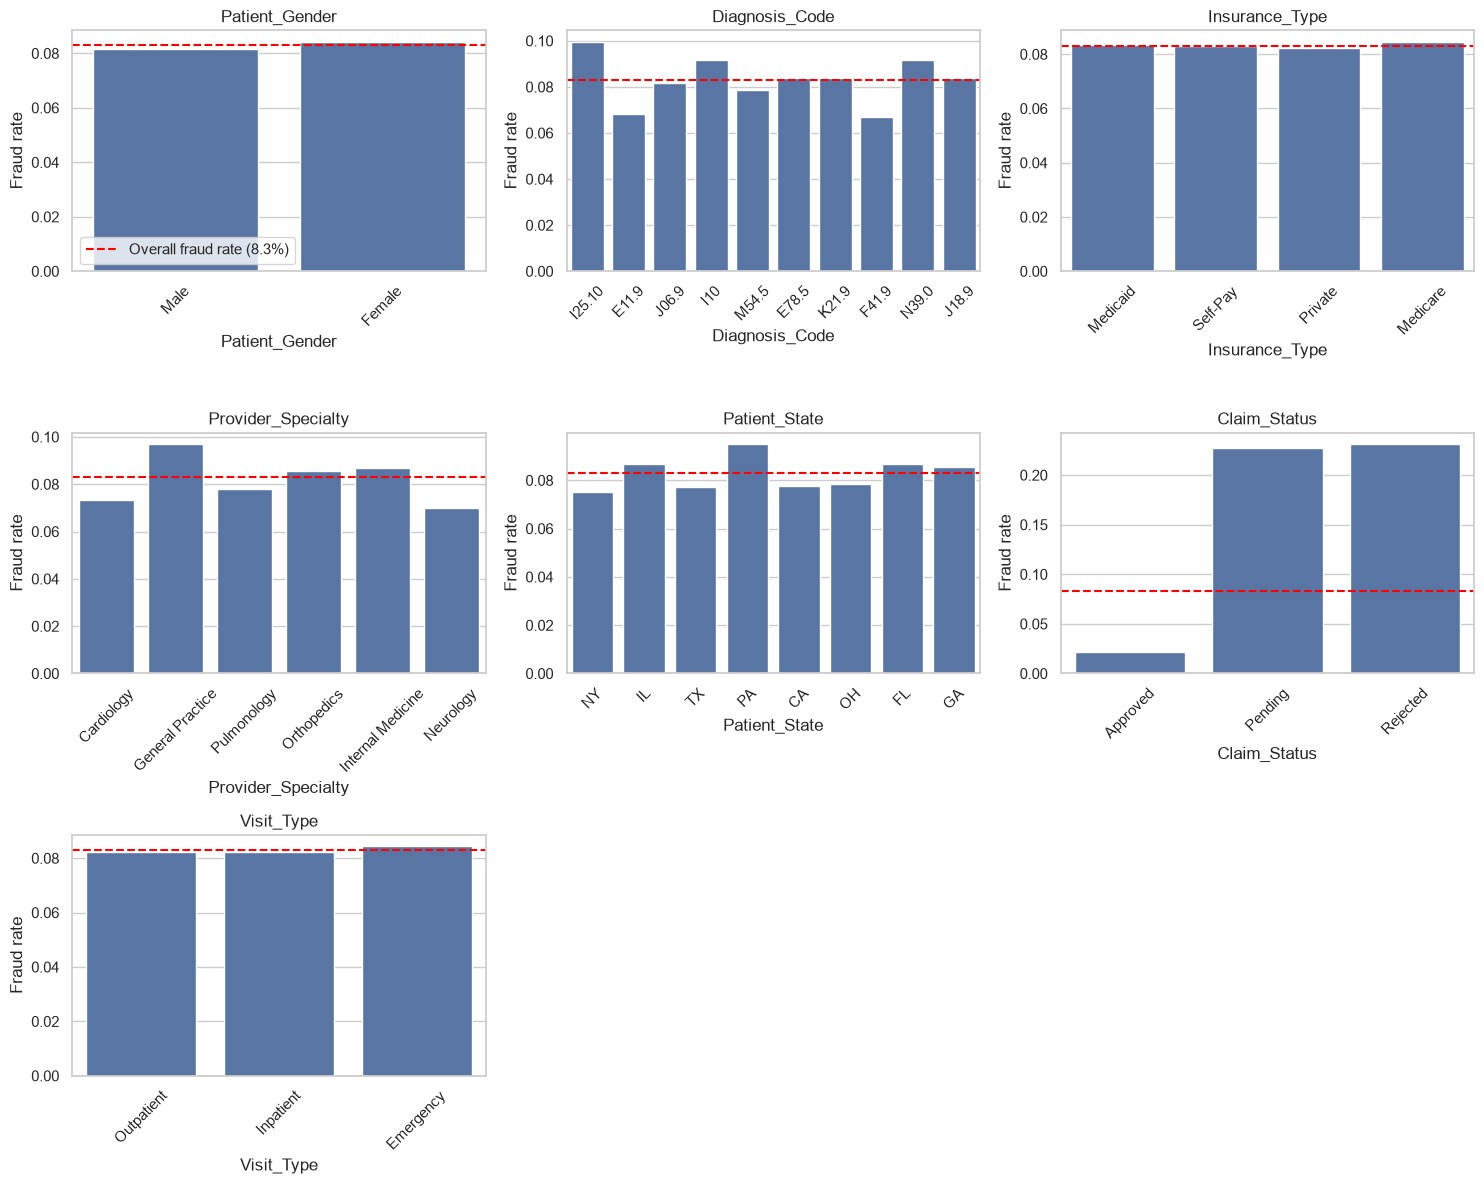

In [35]:
# Plot fraud rate for each category
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, col in zip(axes.flat, cat_cols):
    sns.barplot(data=df, x=col, y="Is_Fraud", errorbar=None, ax=ax)
    ax.axhline(df["Is_Fraud"].mean(), color="red", linestyle="--",
               label=f"Overall fraud rate ({df['Is_Fraud'].mean():.1%})")

    ax.set_title(col)
    ax.set_ylabel("Fraud rate")
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flat[len(cat_cols):]:
    ax.axis("off")
axes.flat[0].legend()
plt.tight_layout()
plt.show()


Most categories sit close to the overall 8.3% fraud rate, so gender, diagnosis, insurance type, specialty, state, and visit type show little relationship with fraud. `Claim_Status` is the only strong pattern: about 23% of Pending and Rejected claims are fraud, compared to 2% of Approved claims. Claim status may be decided after a fraud review, so it could leak the label and should be used with caution.

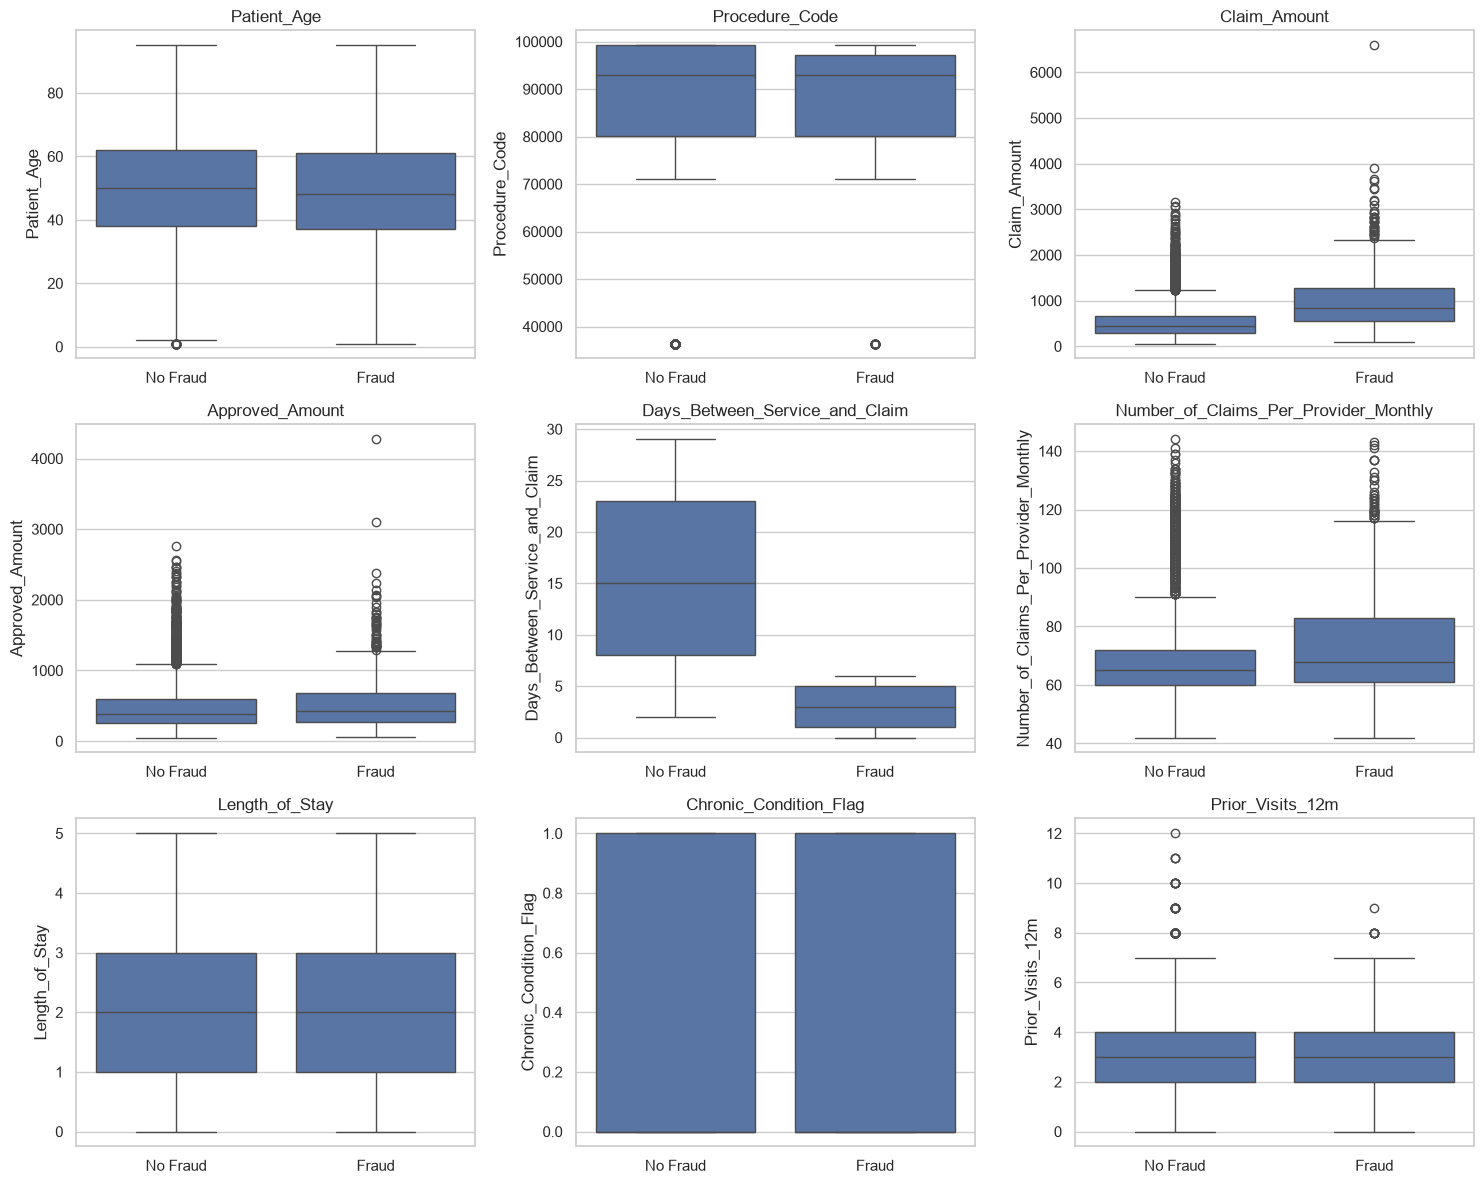

In [36]:
# Boxplots to check for outliers by fraud label
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(data=df, x="Is_Fraud", y=col, ax=ax)
    ax.set_xticks([0, 1], ["No Fraud", "Fraud"])
    ax.set_xlabel("")
    ax.set_title(col)

plt.tight_layout()
plt.show()


`Claim_Amount`, `Approved_Amount`, and `Number_of_Claims_Per_Provider_Monthly` have many high outliers. These outliers are more likely to be fraud: 35% of `Claim_Amount` outliers and 23% of claims-per-provider outliers are fraud, compared to 8% overall. They look like real signal rather than errors, so they should be kept.

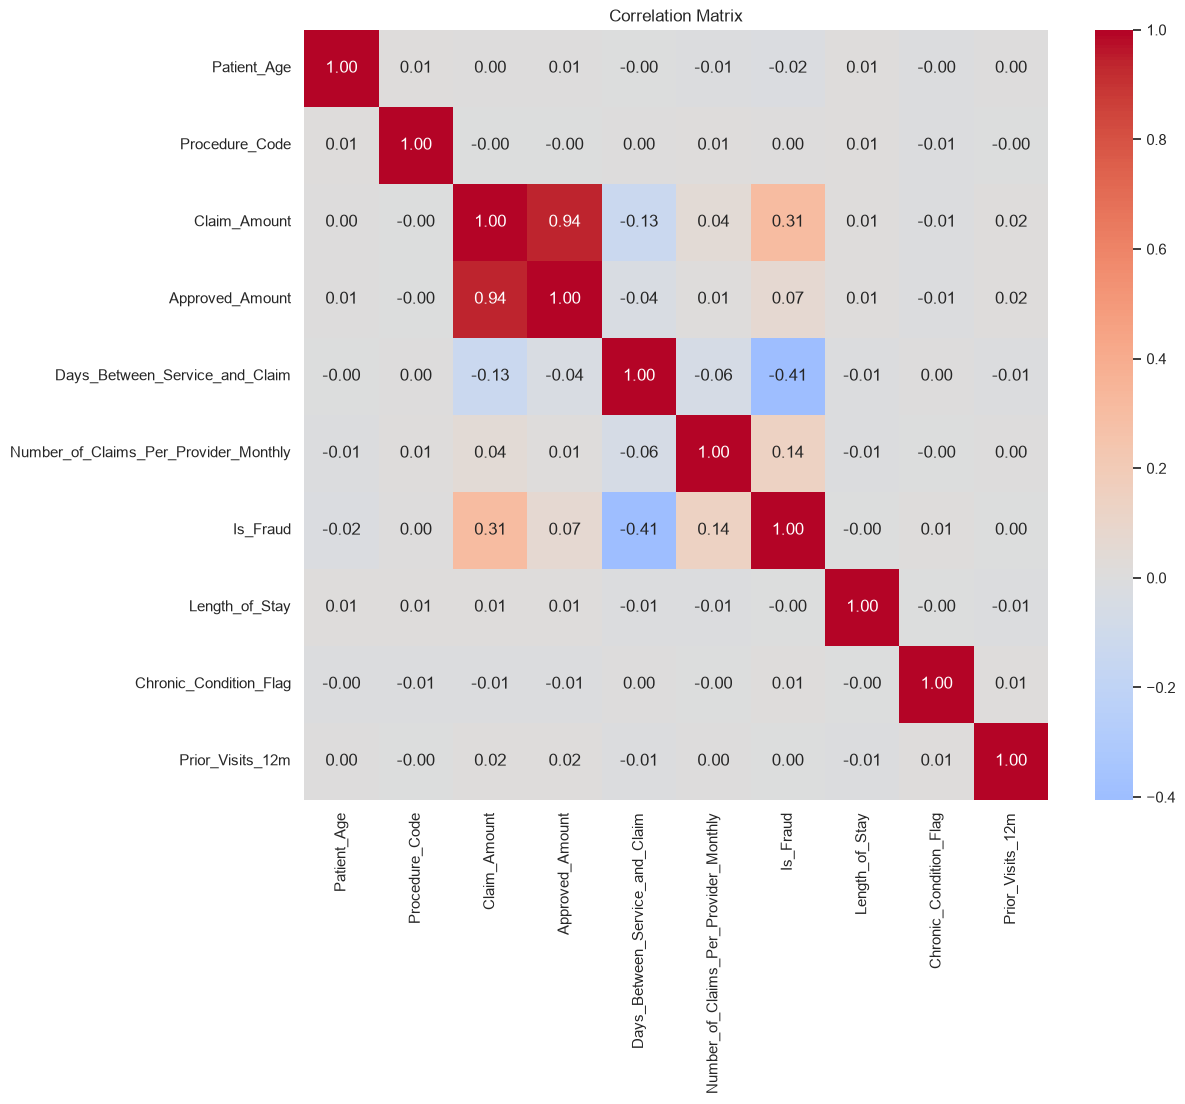

In [37]:
# Plot correlation matrix of numeric columns
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()


`Claim_Amount` and `Approved_Amount` are highly correlated (0.94), so they carry overlapping information. The variables most correlated with `Is_Fraud` are `Days_Between_Service_and_Claim` (-0.41), `Claim_Amount` (0.31), and `Number_of_Claims_Per_Provider_Monthly` (0.14). Everything else is close to 0.

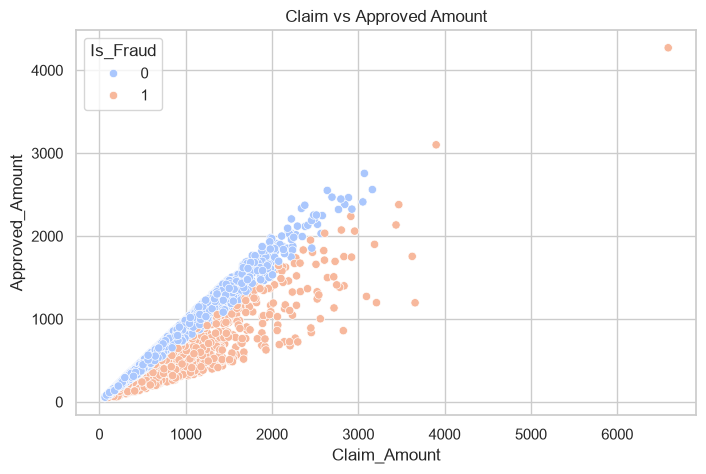

In [38]:
# Plot claim vs approved amount by fraud label
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df, 
    x='Claim_Amount',
    y='Approved_Amount',
    hue='Is_Fraud',
    palette='coolwarm'
)
plt.title("Claim vs Approved Amount")
plt.show()

No-fraud claims fall along a tight band where the approved amount is close to the claimed amount. Fraud claims sit below that band, meaning they are approved for much less than they claim.

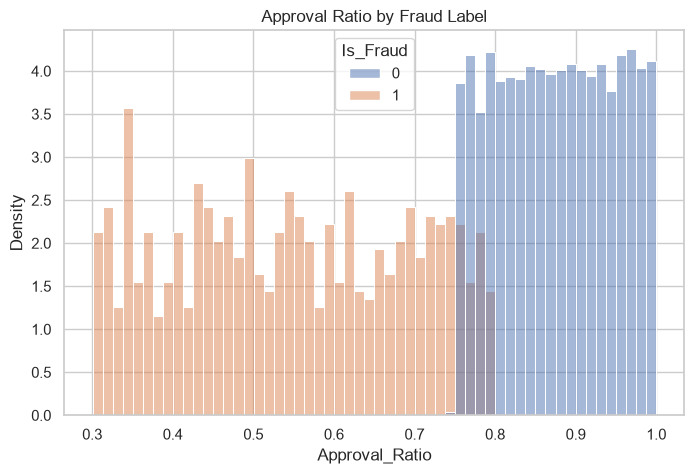

In [39]:
# Create approval ratio and plot by fraud label
df["Approval_Ratio"] = df["Approved_Amount"] / df["Claim_Amount"]

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Approval_Ratio", hue="Is_Fraud", stat="density", common_norm=False)
plt.title("Approval Ratio by Fraud Label")
plt.show()

Approval ratio almost completely separates the classes. No-fraud claims are approved for 75–100% of the claimed amount, while fraud claims are approved for 30–80%.

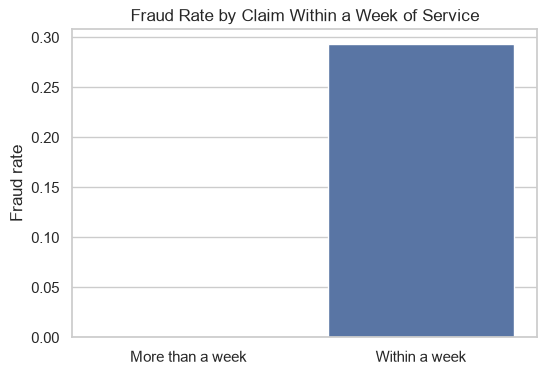

In [40]:
# Flag claims submitted within a week of service
df["Claimed_Within_Week"] = (df["Days_Between_Service_and_Claim"] <= 7).astype(int)

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Claimed_Within_Week", y="Is_Fraud", errorbar=None)
plt.xticks([0, 1], ["More than a week", "Within a week"])
plt.xlabel("")
plt.ylabel("Fraud rate")
plt.title("Fraud Rate by Claim Within a Week of Service")
plt.show()

Every fraud claim was submitted within 7 days of service. About 29% of claims submitted within a week are fraud, compared to 0% of claims submitted later.

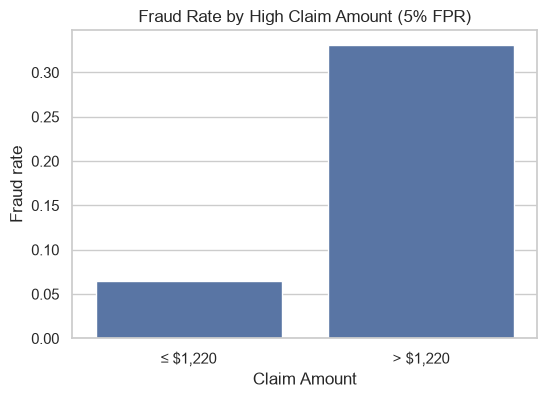

In [41]:
# Flag claims above the claim amount that gives a 5% FPR
threshold = df.loc[df["Is_Fraud"] == 0, "Claim_Amount"].quantile(0.95)
df["High_Claim_Amount"] = (df["Claim_Amount"] > threshold).astype(int)

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="High_Claim_Amount", y="Is_Fraud", errorbar=None)
plt.xticks([0, 1], [f"≤ ${threshold:,.0f}", f"> ${threshold:,.0f}"])
plt.xlabel("Claim Amount")
plt.ylabel("Fraud rate")
plt.title("Fraud Rate by High Claim Amount (5% FPR)")
plt.show()

Claims above \$1,220 (the cutoff where only 5% of no-fraud claims get flagged) have a 33% fraud rate, and the flag catches 27% of fraud claims. It's useful, but weaker than approval ratio and the within-a-week flag.

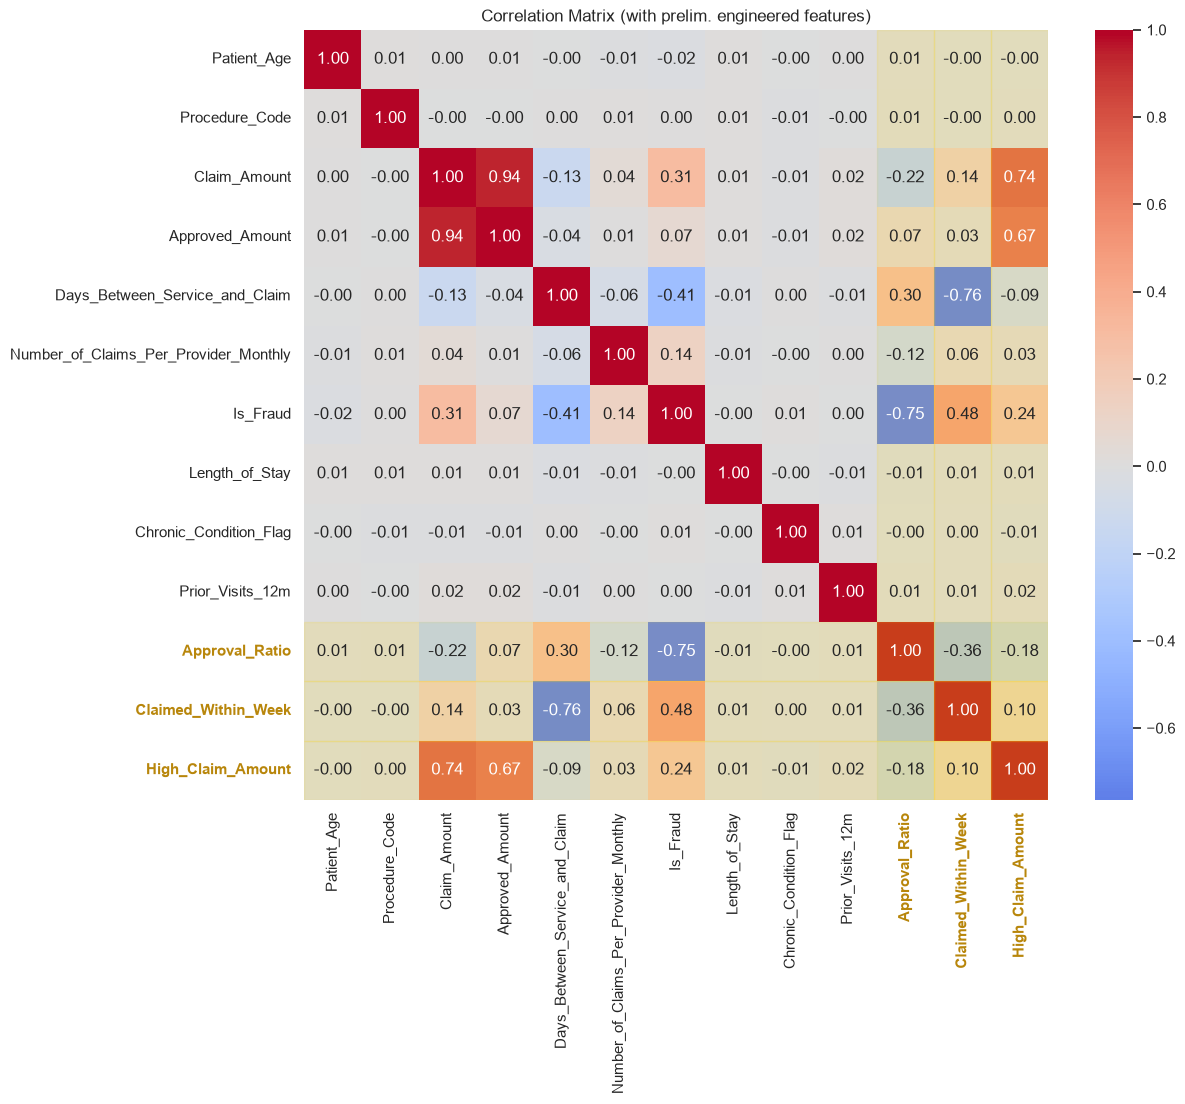

In [42]:
# Plot correlation matrix of numeric columns
corr = df.select_dtypes("number").corr()
engineered = ["Approval_Ratio", "Claimed_Within_Week", "High_Claim_Amount"]

plt.figure(figsize=(12, 10))
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)

# Lightly highlight engineered features
for i, col in enumerate(corr.columns):
    if col in engineered:
        ax.axhspan(i, i + 1, color="gold", alpha=0.15)
        ax.axvspan(i, i + 1, color="gold", alpha=0.15)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    if label.get_text() in engineered:
        label.set_color("darkgoldenrod")
        label.set_fontweight("bold")

plt.title("Correlation Matrix (with prelim. engineered features)")
plt.show()


## Summary of Findings

**Data quality**
- 10,000 claims, 20 columns.
- Only `Insurance_Type`, `Provider_Specialty`, and `Prior_Visits_12m` have missing values (3.5% each). Missingness is about the same for fraud and no fraud, so it can be imputed.
- `Claim_Amount`, `Approved_Amount`, and `Number_of_Claims_Per_Provider_Monthly` have high outliers. These are more likely to be fraud, so they should be kept.

**Class balance**
- 8.3% fraud (829) vs 91.7% no fraud (9,171). Models should be evaluated with recall, precision, and ROC-AUC rather than accuracy.

**Patterns associated with fraud**
- **Submission timing:** every fraud claim was submitted within 7 days of service (median 3 days vs 15 for no fraud).
- **Claim amount:** fraud claims are much larger (median \$831 vs \$443), but approved amounts are only slightly higher.
- **Approval ratio:** fraud claims are approved for 30–80% of the claimed amount, while no-fraud claims are approved for 75–100%.
- **Provider volume:** providers on fraud claims submit slightly more claims per month.
- **Categorical variables:** gender, diagnosis, insurance type, specialty, state, and visit type show little relationship with fraud.
- **Claim status:** Pending and Rejected claims are about 23% fraud vs 2% for Approved. This may leak the label and should be used with caution.

**Engineered features (correlation with `Is_Fraud`)**
- `Approval_Ratio`: -0.75 (strongest of all variables)
- `Claimed_Within_Week`: 0.48
- `High_Claim_Amount`: 0.24

**Next steps**
- Impute missing values and encode categorical variables in preprocessing.
- Keep `Approval_Ratio` and `Claimed_Within_Week` as features. Compute the `High_Claim_Amount` threshold on the training set only to avoid leakage.
- Decide whether to drop `Claim_Status`, and account for class imbalance when modeling.